In [41]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
import squarify
import plotly.express as px

# HISTORIA DE LOS VIDEOJUEGOS: DE LOS 8 BITS AL 4K

## 1. RECOGIDA DE DATOS Y VISUALIZACIÓN

Todos los datos han sido extraídos de la web de Kaggle de diferentes fuentes, obteniendo un total de 7 archivos.

Después hemos procedido a la visualización de los datos. Uno de nuestros archivos descargados, difería en la recogida de datos con los demás, por lo que hemos procedido a descartarlo para este análisis de datos.

## 2. LIMPIEZA DE DATOS

En este paso, hemos procedido a centrarnos en los datos que nos interesaban para nuestro análisis y eliminar aquellas columnas que no nos aportaban nada. Una vez que todos nuestros archivos tenían los mismos tipos de datos, los hemos ordenado. Hemos comparado archivos porque parecían ser iguales. 2 de nuestros archivos eran iguales, por lo que hemos procedido a elimimar uno de ellos. Después de esto, hemos procedido a unir todos los archivos y a guardar este archivo final como csv (videojuegos), que es el que utilizaremos para nuesto análisis de datos.

## 3. HIPÓTESIS

1. Variación de las ventas de videojuegos con el tiempo
2. Videojuegos más vendidos
3. Consolas más populares
4. Fabricante de consolas líder en el sector
5. Géneros de videojuegos más vendidos
6. Géneros de videojuegos más vendidos según el fabricante de las consolas

## 4. ANÁLISIS

En los años 2000 hay una revolución en el sector de los videojuegos debido al desarrollo tecnológico de las consolas, el paso del ADSL a la fibra óptica del internet, y el desarrollo de juegos colaborativos gracias a la mejora del internet. Por esto, vamos a estudiar qué paso con las ventas de videojuegos dividiéndolos en dos épocas: 1980 - 1999 y 2000 - 2020.

### 4.1 VENTAS DE VIDEOJUEGOS A LO LARGO DE LOS AÑOS

Lo que hemos hecho ha sido estudiar las ventas de videojuegos por género, para saber si ha habido algún cambio.

In [42]:
archivo = '../data/videojuegos.csv'
df = pd.read_csv(archivo)
df['Year'] = df['Year'].astype('Int64')

In [43]:
sales_80_90 = (df[(df['Year']>=1980) & (df['Year']<=1999)].groupby('Genre')['Global'].sum().sort_values())
sales_80_90

Genre
Adventure        50.37
Simulation       52.56
Strategy         57.57
Misc             72.01
Puzzle          101.72
Shooter         128.74
Fighting        130.71
Racing          162.50
Sports          178.85
Action          190.52
Role-Playing    199.80
Platform        331.18
Name: Global, dtype: float64

In [44]:
sales_00_20 = (df[(df['Year']>=2000) & (df['Year']<=2020)].groupby('Genre')['Global'].sum().sort_values())
sales_00_20

Genre
Visual Novel           0.48
Party                  0.65
MMO                    5.04
Music                  9.44
Action-Adventure      79.33
Strategy             169.54
Puzzle               229.56
Adventure            299.00
Fighting             483.01
Simulation           559.56
Platform             789.35
Racing               897.76
Misc                1196.72
Role-Playing        1227.92
Shooter             1784.54
Sports              1844.35
Action              2652.40
Name: Global, dtype: float64

Después de visualizar estos datos por época, nos damos cuenta de que ha habido un cambio en las preferencias de género de videojuegos. Los géneros más vendidos de 1980 a 1999 son principalmente Plataformas, y después los de Rol y Acción. Sin embargo, los más vendidos del 2000 a 2020 son principalmente los de Acción, y después los de Deportes y Disparos.

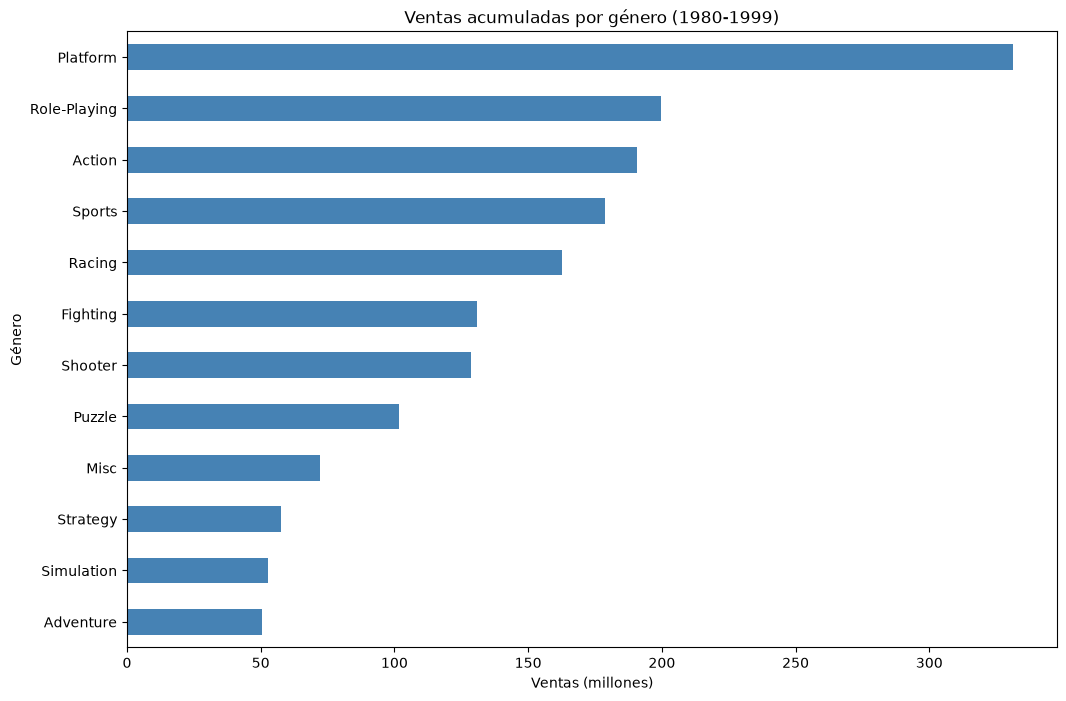

In [45]:
plt.figure(figsize=(12,8))
sales_80_90.plot(
    kind='barh',
    color='steelblue'
)
plt.title('Ventas acumuladas por género (1980-1999)')
plt.xlabel('Ventas (millones)')
plt.ylabel('Género')
plt.show()

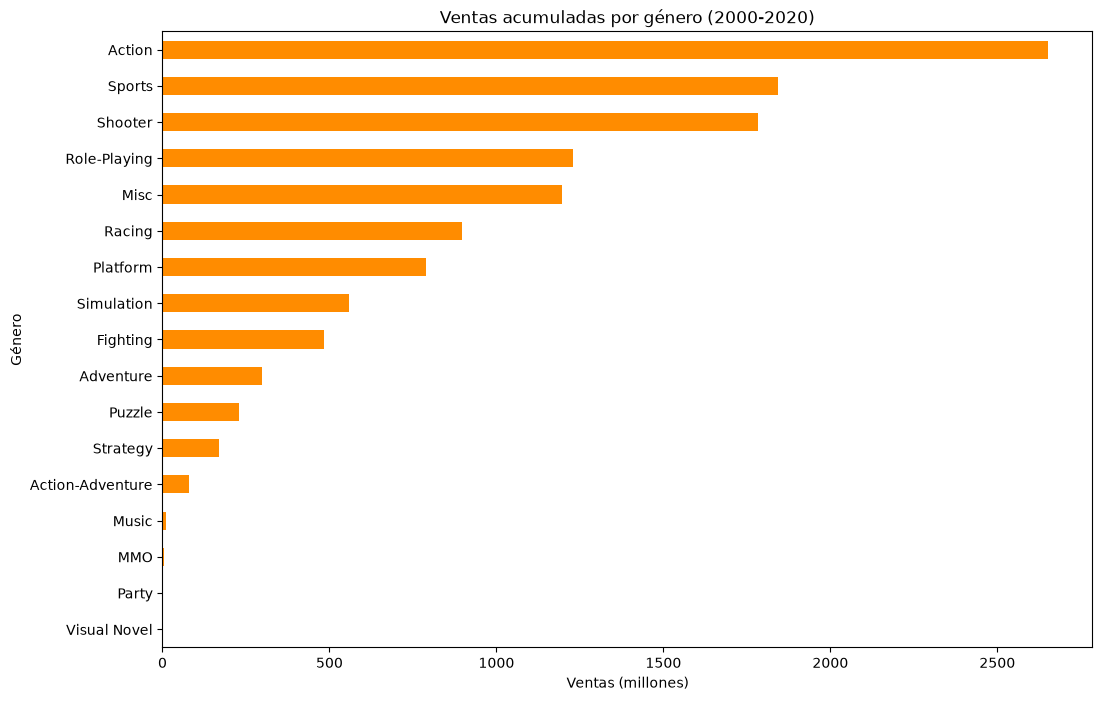

In [46]:
plt.figure(figsize=(12,8))
sales_00_20.plot(
    kind='barh',
    color='darkorange'
)
plt.title('Ventas acumuladas por género (2000-2020)')
plt.xlabel('Ventas (millones)')
plt.ylabel('Género')
plt.show()

Hemos estudiado las ventas de manera global, pero ¿ocurre este mismo cambio por regiones?. Si varían, ¿tienen las mismas tendencias todas las regiones o varían?

In [47]:
def treemap_generos_region(df, region, year_start, year_end):

    sales = (
        df[
            (df['Year'] >= year_start) &
            (df['Year'] <= year_end)
        ]
        .groupby('Genre')[region]
        .sum()
        .reset_index())

    fig = px.treemap(
        sales,
        path=['Genre'],
        values=region,
        color=region,
        color_continuous_scale='Viridis')
    fig.update_traces(
        textinfo='label+percent root',
        textfont_size=20)
    
    fig.update_traces(
        textinfo='label+percent root')

    fig.update_layout(
        title=f'{region} ({year_start}-{year_end})')

    fig.show()

In [48]:
treemap_generos_region(
    df,
    'North America',
    1980,
    1999
)

treemap_generos_region(
    df,
    'Europe',
    1980,
    1999
)

treemap_generos_region(
    df,
    'Japan',
    1980,
    1999
)

treemap_generos_region(
    df,
    'Rest of World',
    1980,
    1999
)

In [49]:
treemap_generos_region(
    df,
    'North America',
    2000,
    2020
)

treemap_generos_region(
    df,
    'Europe',
    2000,
    2020
)

treemap_generos_region(
    df,
    'Japan',
    2000,
    2020
)

treemap_generos_region(
    df,
    'Rest of World',
    2000,
    2020
)

En los 80s y 90s, podemos ver que Norte América y Europa tienen un comportamiento parecido en las ventas de videojuegos por género siendo Plataformas y Acción. 
Mientras que en Japón dominaba los juegos de Rol y Plataformas. Las ventas en el Resto del Mundo se centraban en Plataformas y Rol. En las décadas de los 2000s, 
se ve un cambio en las ventas por género por regiones. Norte América y Europa tienen las mismas tendencias: Acción, Deportes y Disparos. Mientras que Japón, 
sigue manteniendo las ventas en los juegos de Rol mayoritariamente, y después Acción. En el Resto del Mundo, también hay un cambio de ventas en el Resto del Mundo 
cambiando a los géneros de Acción y Deportes.

Después de ver que pasó con las preferencias de videojuegos, siento curiosidad si pasó algo con las ventas de videojuegos y lo relacionaremos con el punto anterior estudiando las ventas de videojuegos en función del género de videojuegos vendidos.

In [50]:
periods = pd.DataFrame({
    '80-99': sales_80_90,
    '00-20': sales_00_20
}).fillna(0)

periods = periods.sort_values('00-20')
periods

,80-99,00-20
Genre,,
Visual Novel,0.00,0.48
Party,0.00,0.65
MMO,0.00,5.04
Music,0.00,9.44
Action-Adventure,0.00,79.33
Strategy,57.57,169.54
Puzzle,101.72,229.56
Adventure,50.37,299.00
Fighting,130.71,483.01


Podemos ver claramente en la tabla que hubo un gran incremento de ventas de videojuegos a partir del año 2000, y que además aparecieron nuevos géneros de videojuegos como el Acción-Aventura, que no existían antes.

Ahora lo que buscamos es una distribución porcentual por región para normalizar los datos.

In [51]:
genre_sales = (df.groupby('Genre')[['North America','Europe','Japan','Rest of World','Global']].sum().sort_values('Global', ascending=False))
genre_sales

,North America,Europe,Japan,Rest of World,Global
Genre,,,,,
Action,1407.69,921.51,231.21,326.16,2888.03
Sports,1023.24,642.96,162.03,219.03,2047.85
Shooter,1033.98,623.00,59.40,211.60,1928.43
Role-Playing,532.81,323.88,470.02,105.41,1432.05
Misc,660.85,364.60,139.72,121.13,1286.90
Platform,582.65,291.14,167.58,81.01,1122.75
Racing,497.51,376.01,74.46,119.04,1067.41
Fighting,312.02,145.75,104.55,56.54,618.84
Simulation,281.77,192.09,87.85,52.51,614.58


In [53]:
genre_pct = (genre_sales[['North America','Europe','Japan','Rest of World']].div(genre_sales[['North America','Europe','Japan','Rest of World']].sum(axis=1),axis=0)* 100)
genre_pct

,North America,Europe,Japan,Rest of World
Genre,,,,
Action,48.766876,31.924048,8.009853,11.299224
Sports,49.980950,31.405879,7.914481,10.698690
Shooter,53.630224,32.313613,3.080945,10.975218
Role-Playing,37.204285,22.615423,32.819875,7.360417
Misc,51.376040,28.344865,10.862163,9.416932
Platform,51.912008,25.939521,14.930772,7.217698
Racing,46.626118,35.239264,6.978313,11.156304
Fighting,50.418511,23.551369,16.893966,9.136154
Simulation,45.874442,31.273811,14.302693,8.549054


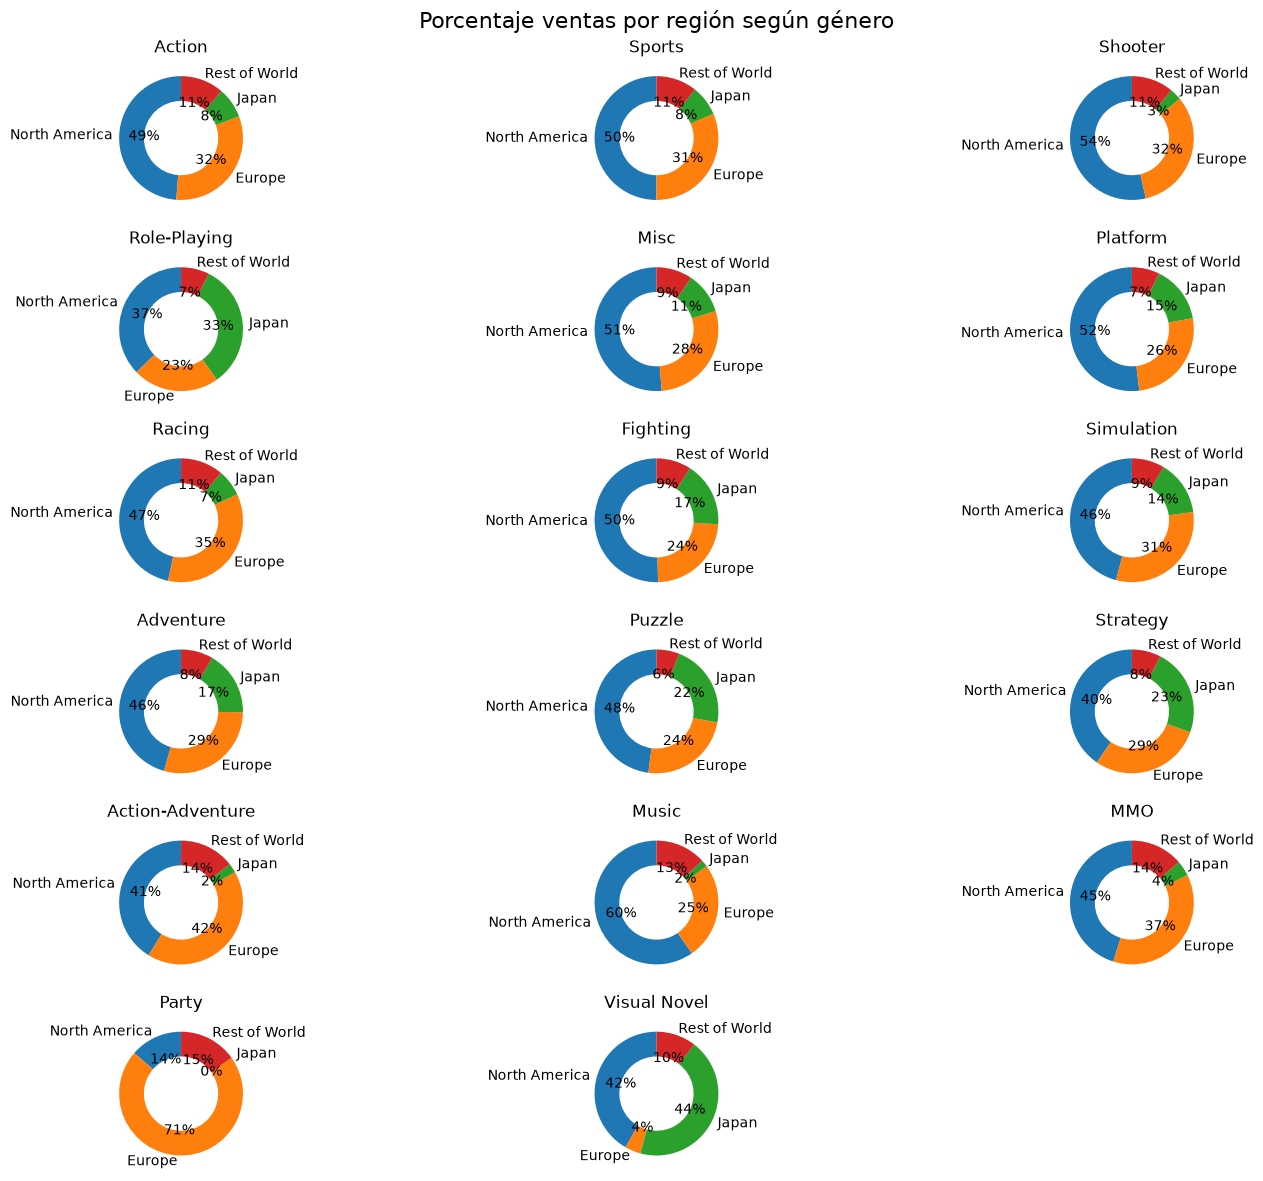

In [54]:
n_genres = len(genre_pct)

fig, axes = plt.subplots(
    nrows=(n_genres+2)//3,
    ncols=3,
    figsize=(15, 12)
)

axes = axes.flatten()

for i, genre in enumerate(genre_pct.index):

    axes[i].pie(
        genre_pct.loc[genre],
        labels=genre_pct.columns,
        autopct='%1.0f%%',
        startangle=90,
        wedgeprops={'width':0.4}
    )

    axes[i].set_title(genre)

# Eliminar ejes vacíos
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    'Porcentaje ventas por región según género',
    fontsize=16
)

plt.tight_layout()
plt.show()

Ahora vamos a representar la variación de ventas de videojuegos por género en las dos épocas.

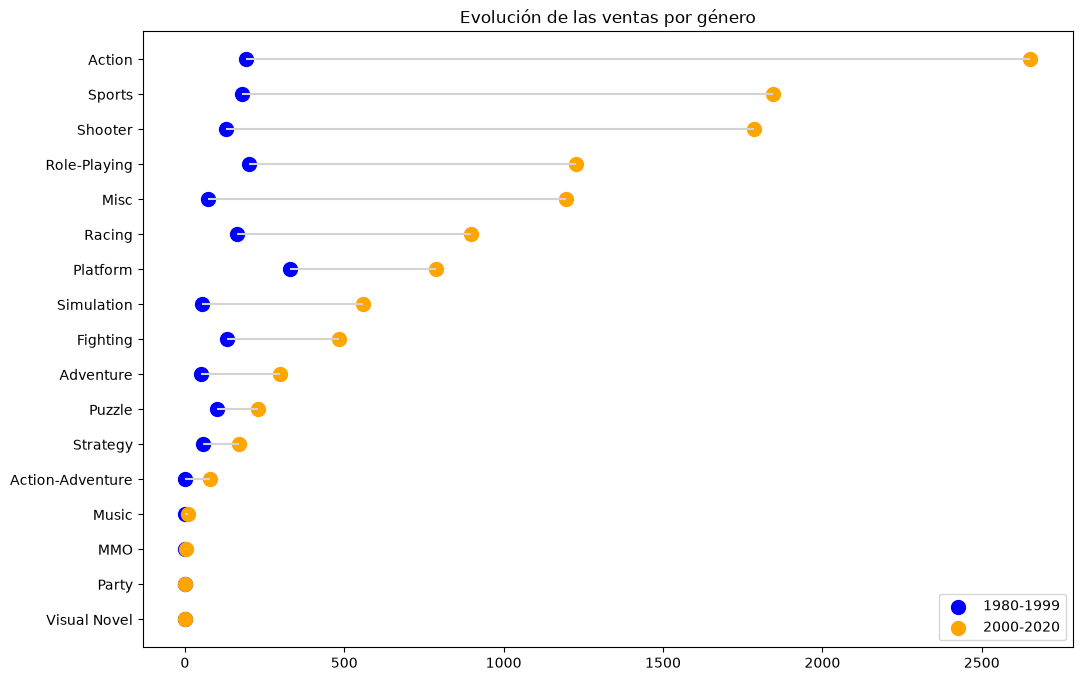

In [11]:
fig, ax = plt.subplots(figsize=(12,8))

ax.hlines(
    y=periods.index,
    xmin=periods['80-99'],
    xmax=periods['00-20'],
    color='lightgray'
)

ax.scatter(
    periods['80-99'],
    periods.index,
    color='blue',
    s=100,
    label='1980-1999'
)

ax.scatter(
    periods['00-20'],
    periods.index,
    color='orange',
    s=100,
    label='2000-2020'
)

ax.legend()

plt.title(
    'Evolución de las ventas por género'
)

plt.show()

Podemos ver que las ventas de videojuegos se incrementaron de manera notable en la mayoría de los géneros.

### 4.2 VIDEOJUEGOS MÁS VENDIDOS - SUPERVENTAS

Una vez que hemos visto qué es lo que ha pasado con las ventas de videojuegos a lo largo del tiempo, vamos a ver ¿cuáles son los videojuegos más vendidos?
Lo primero que hacemos es realizar un análisis descriptivo.

In [12]:
df[['North America','Europe','Japan','Rest of World','Global']].describe()

,North America,Europe,Japan,Rest of World,Global
count,23178.000000,23178.000000,23178.000000,23178.000000,23178.000000
mean,0.292838,0.179921,0.072677,0.059235,0.604891
std,0.868053,0.596062,0.307926,0.203402,1.723504
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.010000,0.000000,0.000000,0.000000,0.060000
50%,0.090000,0.030000,0.000000,0.010000,0.190000
75%,0.270000,0.140000,0.030000,0.050000,0.540000
max,41.490000,29.020000,10.220000,10.570000,82.740000


Este análisis descriptivo no nos aporta mucha información, con respecto a lo que queremos estudiar. 

In [14]:
game_sales = (df.groupby('Game')['Global'].sum().sort_values(ascending=False))
top10_games = game_sales.head(10).sum()
total_sales = game_sales.sum()
(top10_games / total_sales) * 100

np.float64(5.853428206240157)

Este porcentaje de ventas de apenas el 6% para los 10 juegos más vendidos a nivel mundial es muy extraño, por lo que vamos a proceder a investigar este resultado de la siguiente manera: ¿cuántos videojuegos diferentes tengo en realidad? y si difiere mucho o poco del total de videojuegos que tengo.

In [15]:
df['Game'].nunique()

12263

In [16]:
len(df)

23178

Podemos ver que la mitad de mis videojuegos están repetidos, y esto es debido a que se venden para diferentes consolas.

In [17]:
games_df = (df.groupby('Game').agg({'Global': 'sum','North America': 'sum','Europe': 'sum','Japan': 'sum','Rest of World': 'sum'}).reset_index())
top_games = (games_df.sort_values(by='Global',ascending=False).head(20))
top_games

,Game,Global,North America,Europe,Japan,Rest of World
11741,Wii Sports,165.27,82.85,57.98,7.54,16.91
3962,Grand Theft Auto V,140.60,58.06,59.42,3.42,19.71
1326,Call of Duty: Black Ops 3,73.46,34.95,27.14,1.30,10.03
5934,Mario Kart Wii,71.34,31.53,25.64,7.58,6.60
11743,Wii Sports Resort,65.77,31.36,21.94,6.56,5.91
1329,Call of Duty: Ghosts,62.02,33.57,20.44,1.01,6.97
1325,Call of Duty: Black Ops,61.85,35.16,18.85,1.18,6.67
1332,Call of Duty: Modern Warfare 3,61.42,31.12,22.44,1.24,6.64
7137,New Super Mario Bros.,59.81,22.66,18.37,13.00,5.78
1327,Call of Duty: Black Ops II,59.12,28.16,21.89,1.44,7.64


Aunque a nivel global, el videojuego más vendido es el Wii Sports, seguido de Gran Theft Auto V. En este top de los 20 videojuegos más vendidos, se puede ver que la franquicia Call of Duty es la más vendida.

C:\Users\bgran\AppData\Local\Temp\ipykernel_8116\472305704.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


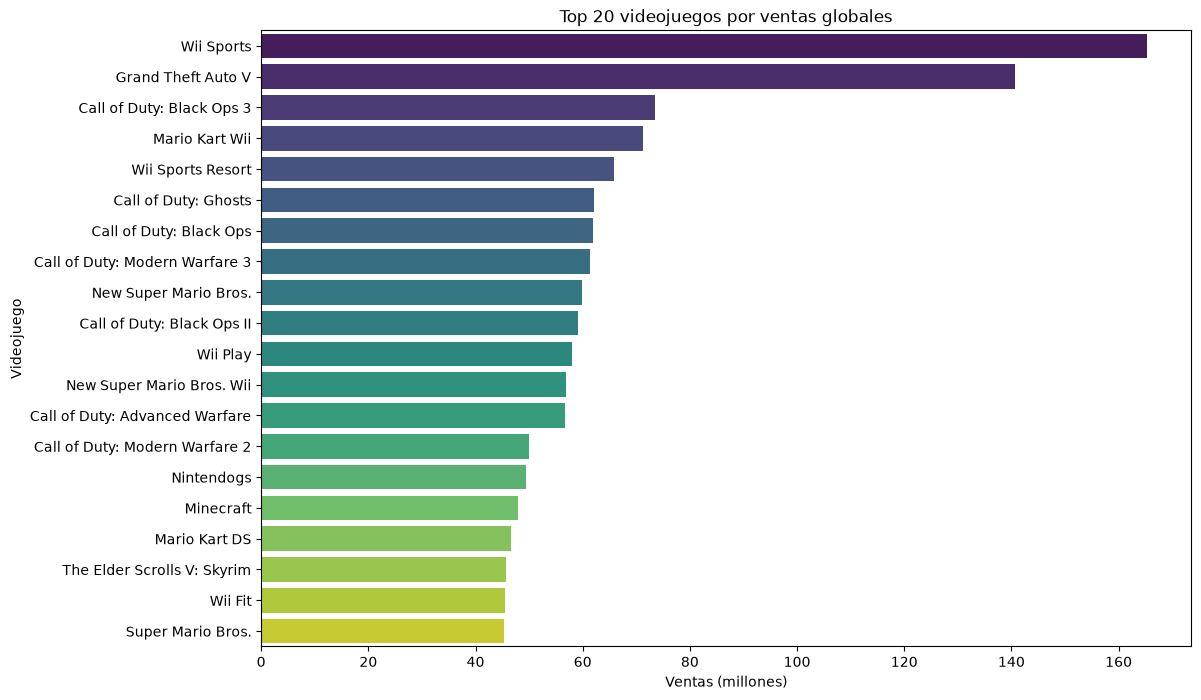

In [18]:
plt.figure(figsize=(12,8))
sns.barplot(
    data=top_games,
    x='Global',
    y='Game',
    palette='viridis'
)
plt.title('Top 20 videojuegos por ventas globales')
plt.xlabel('Ventas (millones)')
plt.ylabel('Videojuego')
plt.show()

Ahora veamos cuáles son los juegos más vendidos en las diferentes regiones.

In [19]:
games_df.nlargest(10,'North America')[['Game', 'North America']]

,Game,North America
11741,Wii Sports,82.85
3962,Grand Theft Auto V,58.06
1325,Call of Duty: Black Ops,35.16
1326,Call of Duty: Black Ops 3,34.95
1329,Call of Duty: Ghosts,33.57
9931,Super Mario Bros.,32.48
5934,Mario Kart Wii,31.53
11743,Wii Sports Resort,31.36
1332,Call of Duty: Modern Warfare 3,31.12
5229,Kinect Adventures!,29.97


In [20]:
games_df.nlargest(10,'Europe')[['Game', 'Europe']]

,Game,Europe
3962,Grand Theft Auto V,59.42
11741,Wii Sports,57.98
3119,FIFA 15,30.30
3120,FIFA 16,30.25
1326,Call of Duty: Black Ops 3,27.14
5934,Mario Kart Wii,25.64
3121,FIFA 17,24.57
1332,Call of Duty: Modern Warfare 3,22.44
3118,FIFA 14,22.10
7213,Nintendogs,21.95


In [21]:
games_df.nlargest(10,'Japan')[['Game', 'Japan']]

,Game,Japan
7137,New Super Mario Bros.,13.00
7796,Pokemon Diamond/Pokemon Pearl,12.08
7790,Pokemon Black/Pokemon White,11.30
388,Animal Crossing: Wild World,10.66
1100,Brain Age 2: More Training in Minutes a Day,10.64
7811,Pokemon Red/Pokemon Blue,10.22
7140,New Super Mario Bros. Wii,9.40
387,Animal Crossing: New Leaf,8.75
2643,Dragon Quest IX: Sentinels of the Starry Skies,8.70
7820,Pokemon X/Pokemon Y,8.69


Aunque a nivel global, el videojuego más vendido es el Wii Sports, seguido de Gran Theft Auto V. En este top de los 20 videojuegos más vendidos, se puede ver que
la franquicia Call of Duty es la más vendida. Con este último análisis, podemos concluir que los gustos de Norte América y Europa son más similares, ya que 
coinciden en los videojuegos de Wii Sports y la franquicia de Call of Duty. Aunque en Norte América, les gusta más los juegos de la franquicia de Super Mario Bros 
y en Europa prefieren la franquicia de la FIFA. Sin embargo, en Japon prefieren la franquicia de Pokemon, Animal Crossing y Super Mario Bros diferiendo mucho de 
los gustos de Norte América y Europa.

Ahora veamos como se comportan las ventas de videojuegos en el mercado, ¿se concentran en unos pocos superventas o no?. Para ello, vamos a utilizar la curva de Pareto.

In [22]:
pareto = (games_df['Global'].sort_values(ascending=False).cumsum()/ games_df['Global'].sum()* 100)
sales = games_df['Global'].sort_values(ascending=False)
pareto = sales.cumsum() / sales.sum() * 100
videojuegos_pct = (np.arange(1, len(sales) + 1)/ len(sales)* 100)
indice_80 = np.argmax(pareto >= 80)
pct_videojuegos = ((indice_80 + 1)/ len(sales)* 100)
pct_videojuegos

np.float64(16.35815053412705)

El resultado nos muestra el 80% de las ventas está acumulada en solo un 16,35% de lo videojuegos. Esto indica que la industria está fuertemente dominada por un grupo relativamente pequeño de videojuegos superventas, mientras que la mayoría de los títulos tienen una contribución mucho más limitada al volumen total de ventas.

En consencuencia, las ventas de videojuegos no se distribuyen de forma uniforme. Un reducido grupo de títulos acumula la mayor parte del mercado, mientras que la mayoría de videojuegos presentan volúmenes de venta considerablemente más bajos.

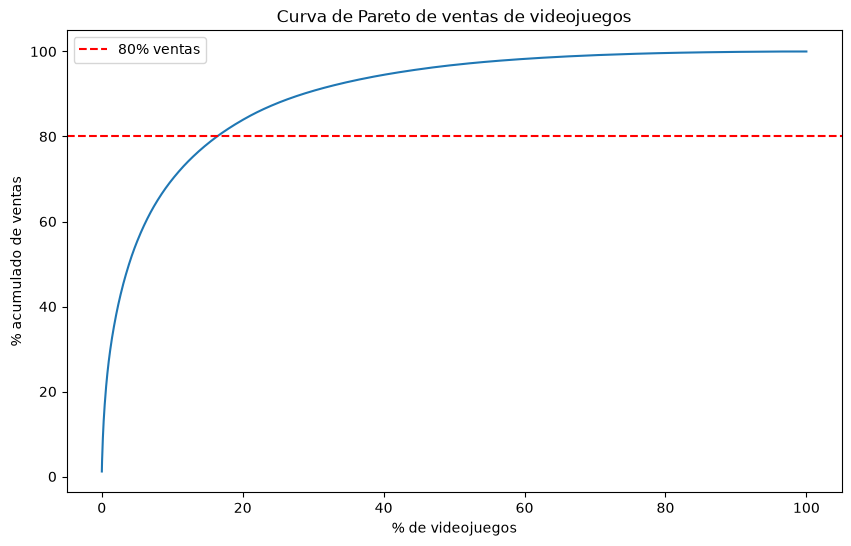

In [23]:
plt.figure(figsize=(10,6))
plt.plot(videojuegos_pct, pareto)
plt.axhline(80,
            color='red',
            linestyle='--',
            label='80% ventas')
plt.xlabel('% de videojuegos')
plt.ylabel('% acumulado de ventas')
plt.title('Curva de Pareto de ventas de videojuegos')
plt.legend()
plt.show()

### 4.3 CONSOLAS

Una vez visto los videojuegos más populares, vamos a ver cuáles son las consolas preferidas en el mundo.

In [24]:
ventas_plataforma = (df.groupby('Platform')['Global'].sum().sort_values(ascending=False).reset_index())
ventas_plataforma.head(10)

,Platform,Global
0,PS3,1816.53
1,X360,1782.26
2,Wii,1770.14
3,DS,1469.45
4,PS2,1256.92
5,PS4,1178.39
6,PS,730.68
7,Xbox One,563.77
8,PSP,464.40
9,3DS,445.84


C:\Users\bgran\AppData\Local\Temp\ipykernel_8116\342067201.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


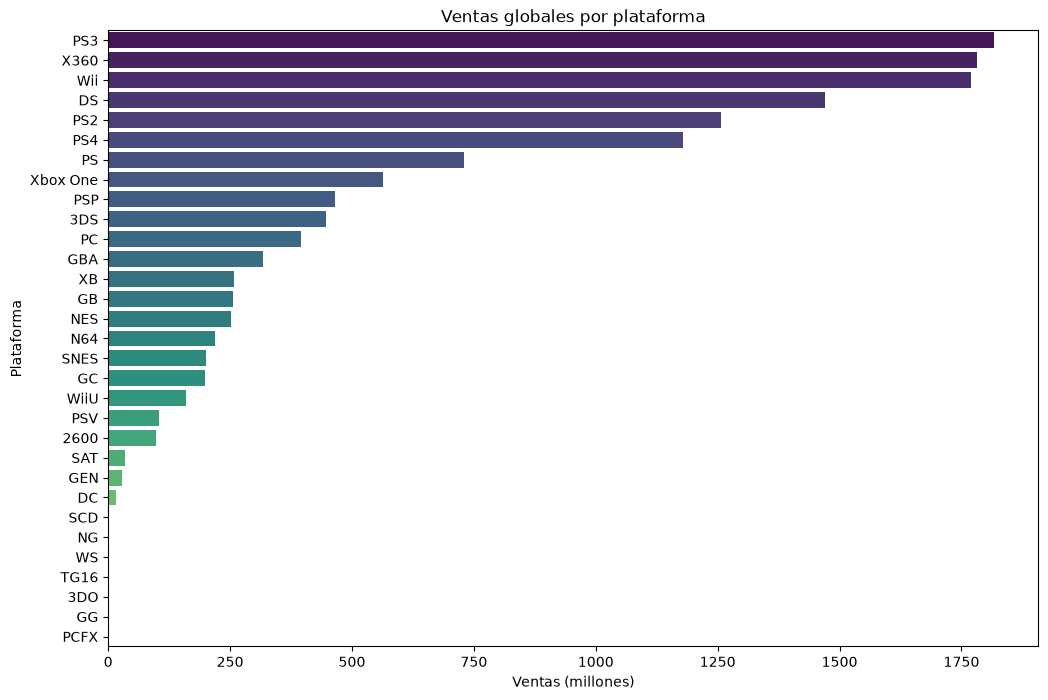

In [25]:
plt.figure(figsize=(12,8))
sns.barplot(
    data=ventas_plataforma,
    x='Global',
    y='Platform',
    palette='viridis'
)
plt.title('Ventas globales por plataforma')
plt.xlabel('Ventas (millones)')
plt.ylabel('Plataforma')
plt.show()

Las consolas más populares a nivel mundial son: la Playstation 3, la XBox 360 y la Wii. Pero, siguen manteniéndose estas mismas consolas en las diferentes regiones estudiadas.

In [30]:
ventas_plataforma_NA = (df.groupby('Platform')['North America'].sum().sort_values(ascending=False).reset_index())
ventas_plataforma_NA.head()

,Platform,North America
0,X360,1086.00
1,Wii,966.22
2,PS3,749.11
3,DS,696.80
4,PS2,584.47


In [31]:
ventas_plataforma_EU = (df.groupby('Platform')['Europe'].sum().sort_values(ascending=False).reset_index())
ventas_plataforma_EU.head()

,Platform,Europe
0,PS3,661.56
1,Wii,520.49
2,PS4,518.48
3,X360,517.54
4,DS,369.56


In [32]:
ventas_plataforma_JP = (df.groupby('Platform')['Japan'].sum().sort_values(ascending=False).reset_index())
ventas_plataforma_JP.head()

,Platform,Japan
0,DS,289.54
1,3DS,164.23
2,PS,139.82
3,PS2,139.20
4,PS3,134.85


In [33]:
ventas_plataforma_RW = (df.groupby('Platform')['Rest of World'].sum().sort_values(ascending=False).reset_index())
ventas_plataforma_RW.head()

,Platform,Rest of World
0,PS3,271.27
1,PS2,193.60
2,PS4,182.72
3,X360,157.63
4,Wii,155.57


Se puede ver que Norte América tiene las mismas preferencias que a nivel mundial. Europa, todavía sigue manteniendo la PlayStation 3 y la Wii y añade la Playstation 4 en vez de la XBox 360. Japón difiere radicalmente, prefiriendo las Nintendo DS y 3DS. Y si nos fijamos en el resto del mundo, se concentran en las Playstation 2, 3 y 4.

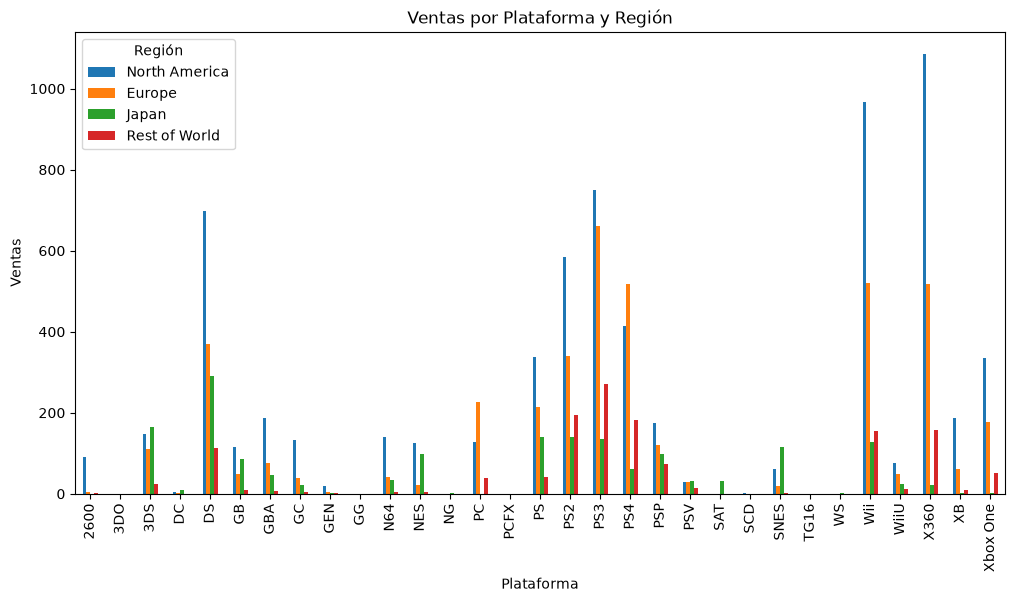

In [34]:
df_plot = df.groupby('Platform')[['North America','Europe','Japan','Rest of World']].sum()
df_plot.plot(kind='bar',figsize=(12,6))
plt.title('Ventas por Plataforma y Región')
plt.xlabel('Plataforma')
plt.ylabel('Ventas')
plt.legend(title='Región')
plt.show()

### 4.4 FABRICANTES DE CONSOLAS

Una vez visto esto, podríamos pensar que las consolas PS3, X360 y Wii son líderes en el sector. Pero, la verdad es que conviven muchas consolas al mismo tiempo de 
un mismo fabricante. Por lo que, lo que tendremos que estudiar realmente es qué fabricante de consolas es realmente líder en el sector en la venta de videojuegos.

In [35]:
ventas_fabricante = (df.groupby('Manufacturer')['Global'].sum().sort_values(ascending=False).reset_index())
ventas_fabricante.head()

,Manufacturer,Global
0,Sony,5551.58
1,Nintendo,5289.06
2,Microsoft,2604.29
3,PC,395.17
4,Atari,97.08


In [36]:
ventas_fabricante_NA = (df.groupby('Manufacturer')['North America'].sum().sort_values(ascending=False).reset_index())
ventas_fabricante_NA.head()

,Manufacturer,North America
0,Nintendo,2646.24
1,Sony,2287.88
2,Microsoft,1608.78
3,PC,127.49
4,Atari,90.60


In [37]:
ventas_fabricante_EU = (df.groupby('Manufacturer')['Europe'].sum().sort_values(ascending=False).reset_index())
ventas_fabricante_EU.head()

,Manufacturer,Europe
0,Sony,1882.52
1,Nintendo,1292.26
2,Microsoft,754.66
3,PC,227.19
4,Sega,8.11


In [38]:
ventas_fabricante_JP = (df.groupby('Manufacturer')['Japan'].sum().sort_values(ascending=False).reset_index())
ventas_fabricante_JP.head()

,Manufacturer,Japan
0,Nintendo,1009.03
1,Sony,605.03
2,Sega,43.98
3,Microsoft,23.14
4,SNK,1.44


In [39]:
ventas_fabricante_RW = (df.groupby('Manufacturer')['Rest of World'].sum().sort_values(ascending=False).reset_index())
ventas_fabricante_RW.head()

,Manufacturer,Rest of World
0,Sony,776.58
1,Nintendo,338.16
2,Microsoft,216.57
3,PC,39.44
4,Sega,1.28


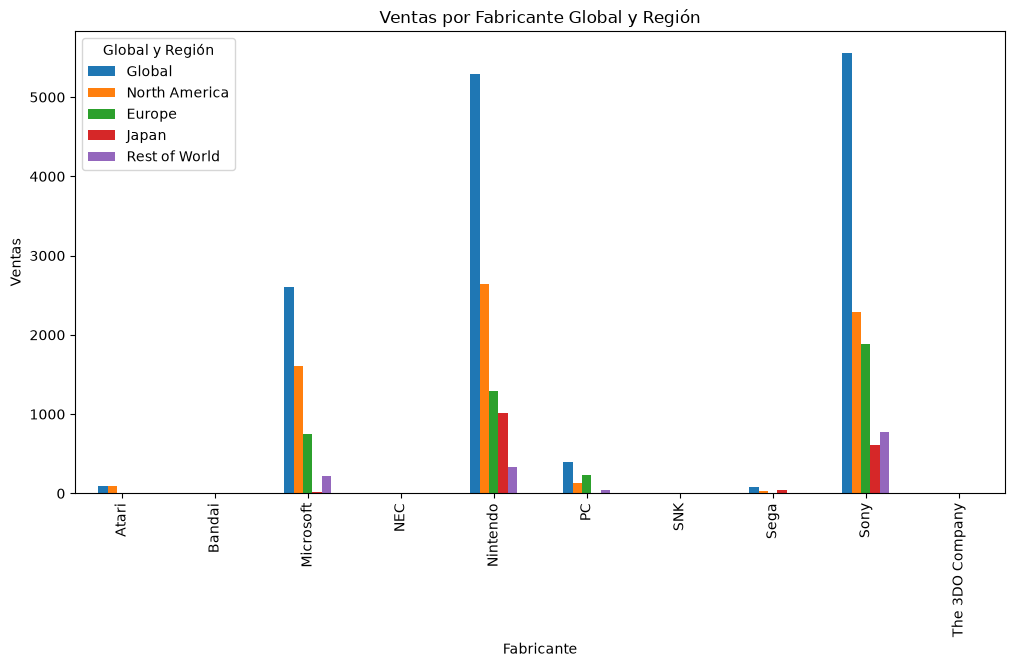

In [40]:
df_plot = df.groupby('Manufacturer')[['Global','North America','Europe','Japan','Rest of World']].sum()
df_plot.plot(kind='bar',figsize=(12,6))
plt.title('Ventas por Fabricante Global y Región')
plt.xlabel('Fabricante')
plt.ylabel('Ventas')
plt.legend(title='Global y Región')
plt.show()

Si analizamos las ventas por fabricante de las plataformas y las comparamos con las ventas globales y por regiones según las plataformas, nos podemos dar cuenta de que las PS3 (Sony), X360 (Microsoft) y Wii (Nintendo) eran quienes dominaban las ventas por plataforma; las ventas de videojuegos por fabricante es dominada claramente por Sony y Nintendo tanto a nivel Global y por Regiones.

### 4.5 VENTAS DE TIPOS DE VIDEOJUEGOS POR FABRICANTE

Hemos analizado qué ha pasado con los videojuegos a lo largo de los años, los videojuegos más vendidos, las consolas preferidas y qué fabricantes de consolas son líderes en la ventas de videojuegos. Un análisis interesante sería ver, qué géneros de videojuegos vende cada fabricante para saber si tienen el mismo público objetivo o no.

Los fabricantes líderes son: Sony y Nintendo, seguido de Microsoft, como ya hemos visto anteriormente.

In [55]:
sony = (
    df[df['Manufacturer'] == 'Sony']
    .groupby(['Manufacturer', 'Genre'])[
        ['Global', 'North America', 'Europe', 'Japan', 'Rest of World']
    ]
    .sum()
    .sort_values('Global', ascending=False)
    .reset_index()
)
sony.head()

,Manufacturer,Genre,Global,North America,Europe,Japan,Rest of World
0,Sony,Action,1452.70,589.20,511.09,132.71,219.43
1,Sony,Sports,894.26,397.35,303.41,65.82,127.91
2,Sony,Shooter,866.43,368.48,335.65,33.93,128.47
3,Sony,Role-Playing,527.72,175.53,123.59,174.95,53.96
4,Sony,Racing,520.69,212.70,202.08,26.23,79.74


In [56]:
nintendo = (
    df[df['Manufacturer'] == 'Nintendo']
    .groupby(['Manufacturer', 'Genre'])[
        ['Global', 'North America', 'Europe', 'Japan', 'Rest of World']
    ]
    .sum()
    .sort_values('Global', ascending=False)
    .reset_index()
)
nintendo.head()

,Manufacturer,Genre,Global,North America,Europe,Japan,Rest of World
0,Nintendo,Platform,790.76,414.08,179.52,153.64,43.27
1,Nintendo,Misc,783.76,393.76,222.56,107.37,59.69
2,Nintendo,Sports,760.49,386.01,222.88,91.16,60.05
3,Nintendo,Action,731.35,407.58,183.22,91.81,48.01
4,Nintendo,Role-Playing,632.12,214.47,105.16,284.51,27.85


In [57]:
microsoft = (
    df[df['Manufacturer'] == 'Microsoft']
    .groupby(['Manufacturer', 'Genre'])[
        ['Global', 'North America', 'Europe', 'Japan', 'Rest of World']
    ]
    .sum()
    .sort_values('Global', ascending=False)
    .reset_index()
)
microsoft.head()

,Manufacturer,Genre,Global,North America,Europe,Japan,Rest of World
0,Microsoft,Shooter,797.39,504.37,219.34,6.23,67.26
1,Microsoft,Action,619.06,366.54,194.25,5.20,52.81
2,Microsoft,Sports,363.29,231.33,102.05,0.83,28.67
3,Microsoft,Misc,200.21,136.40,46.71,0.82,16.30
4,Microsoft,Racing,190.93,99.37,74.06,1.30,16.11


In [58]:
genre_manufacturer = (df.groupby(['Manufacturer', 'Genre'])['Global'].sum().reset_index())
fig = px.treemap(
    genre_manufacturer,
    path=['Manufacturer', 'Genre'],
    values='Global',
    color='Global',
    color_continuous_scale='Turbo'
)

fig.show()

Sony tiene un porcentaje muy alto de sus ventas en los juegos de Acción, seguidos por Deportes, Disparos, y luego por Rol y Carreras. Mientras que en Nintendo, tiene una distribución de géneros más equitativa entre los de Plataformas, Juegos Variados, Deportes, Acción y Rol. Las ventas de Microsoft se centran en los géneros de Disparos y Acción.

Ahora estudiemos el comportamiento de las ventas en las diferentes regiones.

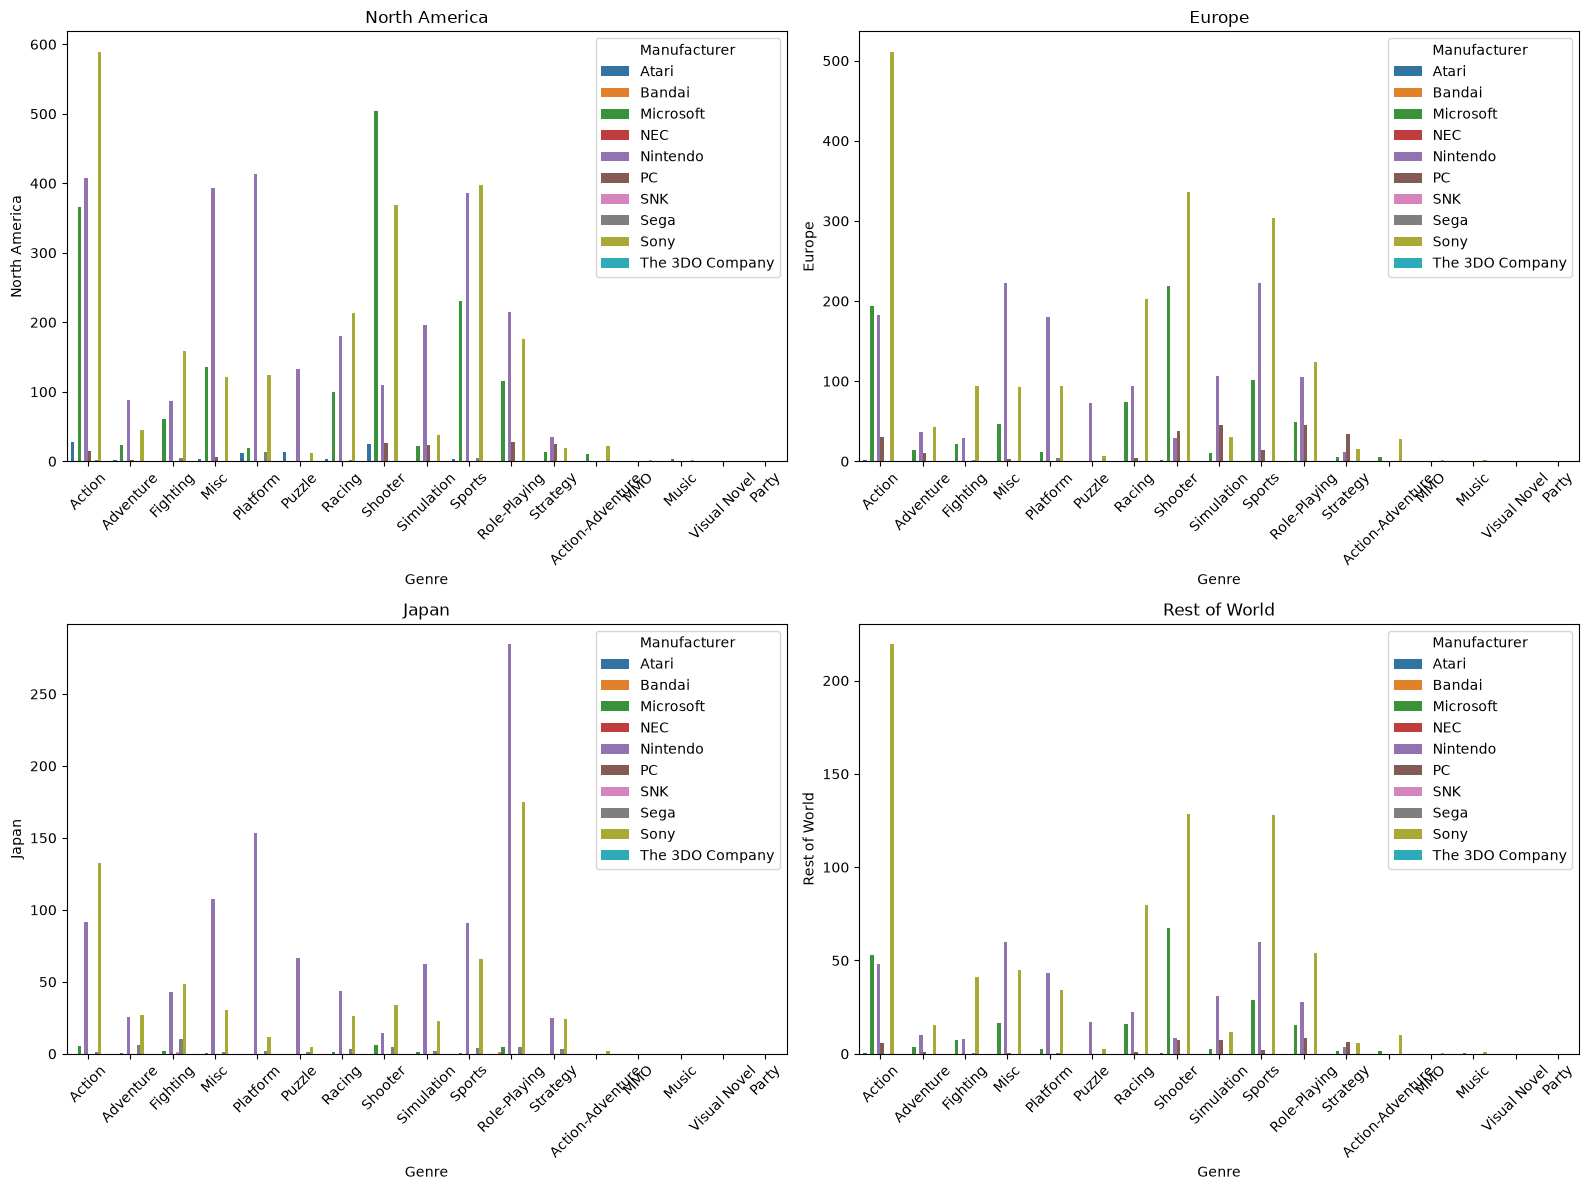

In [ ]:
genre_region_manufacturer = (df.groupby(['Manufacturer','Genre'])[['North America','Europe','Japan','Rest of World']].sum())

fig, axes = plt.subplots(
    2, 2,
    figsize=(16,12)
)

regions = [
    'North America',
    'Europe',
    'Japan',
    'Rest of World'
]

for ax, region in zip(axes.flatten(), regions):

    data = (
        genre_region_manufacturer[region]
        .reset_index()
    )

    sns.barplot(
        data=data,
        x='Genre',
        y=region,
        hue='Manufacturer',
        ax=ax
    )

    ax.set_title(region)
    ax.tick_params(axis='x', rotation=45)6

plt.tight_layout()
plt.show()

Analizando las gráficas por regiones, en Norte América se puede visualizar que el género más vendido es el de Acción y que el fabricante que lo lidera es Sony. El siguiente género más vendido es el de disparos por Microsoft. Después le siguen los géneros Juegos Variados, Plataformas y Deportes. Los dos primeros están liderados por Nintendo, mientras que Deportes está muy igualado en ventas tanto Sony como Nintendo.
En Europa, el género más vendido también es Acción por el fabricante de Sony. Le siguen Disparos y Deportes también de Sony, y por último Plataformas y Juegos Variados por Nintendo.
Ahora podemos ver un cambio radical en la venta en Japón, ya que los juegos más vendidos son los de Rol de Nintendo. Luego le siguen los de Plataformas de Nintendo, y de unas ventas similares son los Juegos Variados de Nintendo y los de Acción de Sony.
En el resto del mundo podemos ver un comportamiento similar a Europa y Norte América, liderando el sector el género de Acción por el fabricante Sony, y después de forma muy igualada Disparos y Deportes también por parte de Sony.

## 5. CONCLUSIONES

Con los avances tecnológicos en los años 2000s, como la gran evolución de las consolas como por ejemplo en sus procesadores y tarjetas gráficas, el avance del ADSL a la fibra óptica, podemos concluir primeramente:

- Hay un gran incremento en las ventas de videojuegos.

- Cambian las preferencias en los géneros de videojuegos más vendidos: de ser los más vendidos los juegos de Plataformas, seguidos por Rol y Acción a que principalmente se vendan los de Acción, seguidos por Deportes y Disparos. Al estudiar esto mismo por regiones, todas las regiones siguen las tendencias globales excepto Japón, que se mantiene fiel a los juegos de Rol.

- Al analizar las ventas por regiones, se puede ver que Norte América vende más videojuegos en general de cualquier género, y después Europa. Aunque Japón, produce una anomalía en los videojuegos de rol, ya que clase iguala en ventas a Norte América y supera a Europa.

- Además de esto, podemos ver que en los años 2000s aparecen nuevos géneros como los de Acción-Aventura.

- Los videojuegos más vendidos son Wii Sports, Grand Theft Auto V y la franquicia de Call of Duty a nivel global. En cambio por regiones, Norte América y Europa tienen gustos similares siguiendo las tendencias globales. Sin embargo, en Japón prefieren las franquicias de Pokemon, Animal Crossing y Super Mario Bros.

- Las ventas de los videojuegos están concentradas en unos pocos superventas.

- Las consolas más populares a nivel mundial son: PS3, X360 y Wii. En el estudio por regiones, Norte América sigue las tendencias globales, Europa también tiene una tendencia similar aunque cambia la X360 por la PS4. Sin embargo, en Japón las consolas más populares son la Nintendo DS y 3DS, mientras que en el Resto del Mundo, las consolas más populares se centran en las diferentes versiones de la Playstation (PS2, PS3 y PS4).

- Los líderes de fabricantes de consolas son: Sony y Nintendo, seguido de lejos por Microsoft.

- Los géneros más vendidos por fabricantes a nivel Global son: Acción principalmente, y de después, de manera más equilibrada Deportes y Disparos por Sony; Plataforma, Juegos Variados, Deportes y Acción de manera muy equilibrada por Nintendo; Disparos y Acción principalmente por Microsoft. Si lo analizamos por regiones, las ventas de Sony siguen las tendencias globales en todas las regiones excepto en Japón, que vende principalmente de Rol y Acción; Nintendo también mantiene las tendencias globales en las diferentes regiones, exceptuando a Japón, que vende mayoritariamente juegos de Rol, Plataformas y Juegos Variados. Microsoft también sigue las tendencias globales en todas las regiones, exceptuando en Japón que a penas tiene presencia en esta región.